In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob    # to understad the meaning of sentence
from wordcloud import WordCloud


data = pd.read_csv("/content/Sentiment_Analysis .csv")

In [ ]:
data.head()

,Sentences
0,The product's exceptional quality and performa...
1,Poor customer support and the product's subpar...
2,The service met standard requirements without ...
3,Outstanding customer service accompanied the p...
4,The product's failure to meet basic requiremen...


In [ ]:
# meaning is basically tone and python called it polarity

def get_sentiment(text):
  meaning = textblob(text)

  if meaning.sentiment.polarity > 0:
    return "Positive"

  elif meaning.sentiment.polarity < 0:
    return "Negative"

  else:
    "Netural"

In [ ]:

data["Sentiment"] = data["Sentences"].apply(get_sentiment)

In [ ]:
data.head(8)

,Sentences,Sentiment
0,The product's exceptional quality and performa...,Positive
1,Poor customer support and the product's subpar...,Negative
2,The service met standard requirements without ...,Positive
3,Outstanding customer service accompanied the p...,Positive
4,The product's failure to meet basic requiremen...,Negative
5,The service provided met basic needs without n...,Positive
6,Remarkable product quality and performance exc...,Positive
7,Poor customer service and a faulty product led...,Negative


In [ ]:
data.to_excel("Sentiment_analysis.xlsx", index = False)

In [ ]:
negative_reviews = data[data["Sentiment"] == "Negative"]

In [ ]:
negative_reviews.head(10)

,Sentences,Sentiment
1,Poor customer support and the product's subpar...,Negative
4,The product's failure to meet basic requiremen...,Negative
7,Poor customer service and a faulty product led...,Negative
8,"The service provided was average, meeting mini...",Negative
13,Dreadful customer support coupled with a defec...,Negative
16,Severe product shortcomings led to considerabl...,Negative
17,"The service was standard, meeting basic needs ...",Negative
19,Disappointing product quality and poor custome...,Negative
20,"The service provided was average, meeting basi...",Negative


In [ ]:
negative_para = " ".join(negative_reviews["Sentences"])

In [ ]:
print(negative_para)

Poor customer support and the product's subpar performance led to frustration and disappointment, regretting the purchase entirely. The product's failure to meet basic requirements resulted in immense inconvenience and frustration, causing regret over the purchase. Poor customer service and a faulty product led to significant inconvenience and frustration, resulting in regret over the purchase decision. The service provided was average, meeting minimum requirements without standout features, resulting in a standard user experience. Dreadful customer support coupled with a defective product caused immense frustration and disappointment, regretting the purchase. Severe product shortcomings led to considerable dissatisfaction and regret over the purchase due to a lack of promised functionality. The service was standard, meeting basic needs without noteworthy features, resulting in an average user experience without extremes. Disappointing product quality and poor customer service resulted

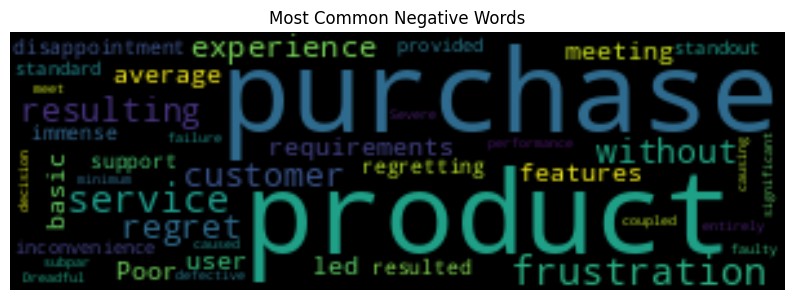

In [ ]:
wordcloud = WordCloud( height = 100 , width =300 , background_color= "black").generate(negative_para)

plt.figure(figsize=(10,6))
plt.imshow(wordcloud , interpolation= "Bilinear")
plt.title("Most Common Negative Words")
plt.axis("off")
plt.show()